In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import(
    accuracy_score,
    confusion_matrix,
    classification_report)

In [4]:
data={
    "StudyHours":[
        1,2,2,3,3,4,4,5,
        5,6,6,7,7,8,8,9,
        2,3,4,6,7,5,8,9
    ],
    "Attendance":[
        40,45,50,50,55,55,60,65,
        70,70,75,80,85,85,90,95,
        60,65,70,80,75,60,95,90
    ],
    "Result":[
        "Fail","Fail","Fail","Fail",
        "Fail","Fail","Fail","Fail",
        "Pass","Pass","Pass","Pass",
        "Pass","Pass","Pass","Pass",
        "Fail","Fail","Fail","Pass",
        "Pass","Fail","Pass","Pass"
    ]
}

df=pd.DataFrame(data)

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nClass counts:")
print(df["Result"].value_counts())


   StudyHours  Attendance Result
0           1          40   Fail
1           2          45   Fail
2           2          50   Fail
3           3          50   Fail
4           3          55   Fail

Dataset Shape: (24, 3)

Class counts:
Fail    12
Pass    12
Name: Result, dtype: int64


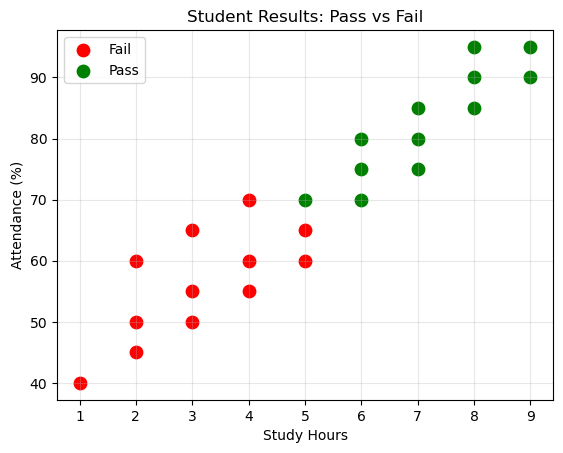

In [14]:
#Visulaize the dataset

colors={"Pass": "green", "Fail":"red"}

for result,group in df.groupby("Result"):
    plt.scatter(
    group["StudyHours"],
    group["Attendance"],
    label=result,
    color=colors[result],
    s=80
    )
    
plt.xlabel("Study Hours")
plt.ylabel("Attendance (%)")
plt.title("Student Results: Pass vs Fail")
plt.legend()
plt.grid(True,alpha=0.3)

In [15]:
#Separate features and target

X=df[["StudyHours", "Attendance"]]
y=df["Result"]

print("Features:")
print(X.head())

print("\nTarget Labels:")
print(y.head())

Features:
   StudyHours  Attendance
0           1          40
1           2          45
2           2          50
3           3          50
4           3          55

Target Labels:
0    Fail
1    Fail
2    Fail
3    Fail
4    Fail
Name: Result, dtype: object


In [16]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.25,
    random_state=42,
    stratify=y)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 18
Testing samples: 6


In [17]:
#Scale the features
scalar=StandardScaler()

X_train_scaled= scalar.fit_transform(X_train)
X_test_scaled= scalar.transform(X_test)
print("First 5 scaled training observations:")
print(X_train_scaled[:5])

First 5 scaled training observations:
[[-0.82754705 -0.21693046]
 [ 0.92490553  1.08465229]
 [ 0.48679238  0.10846523]
 [-1.2656602  -1.19311752]
 [-0.38943391 -0.86772183]]


In [18]:
#Build and train the KNN model

#n_neidhbors=3 sets (K=3)
#fit() stores the training observations and their labels.
#No traditional equation is learned as in linear regression

knn=KNeighborsClassifier(n_neighbors=3)

knn.fit(X_train_scaled, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [21]:
#Make predictions
y_pred=knn.predict(X_test_scaled)

results=pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": y_pred
})
print(results)

  Actual Predicted
0   Fail      Fail
1   Pass      Pass
2   Pass      Pass
3   Pass      Pass
4   Fail      Fail
5   Fail      Pass


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\neighbors\_classification.py:228: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode, _ = stats.mode(_y[neigh_ind, k], axis=1)


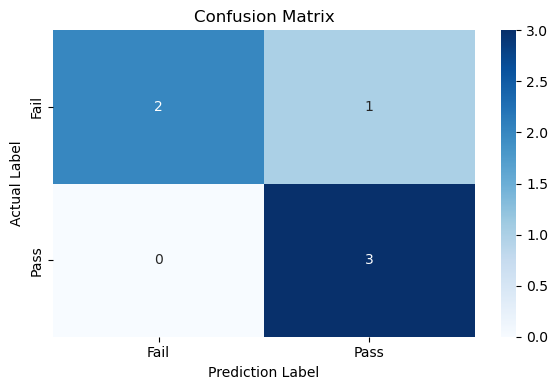

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

#Create confusion matrix
cm=confusion_matrix(
    y_test,
    y_pred,
    labels=["Fail","Pass"]
)

#Visulaize confusionmatrix
plt.figure(figsize=(6,4))
sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Fail","Pass"],
        yticklabels=["Fail","Pass"]
        )
plt.title("Confusion Matrix")
plt.xlabel("Prediction Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()